# Robustness of metric and non-metric MDS to high-dimensional noise

Makes the figure `robustness` and prints the slopes for the appendix table from the results of
`code/mds_robustness.py` (nothing is simulated here). Run first, from the repository root:

```
uv run python code/mds_robustness.py --jobs 8
```

(all six settings, 10 repetitions each; the kNN accuracy is averaged over the repetitions before the breaking
dimensionality is read off). Metric and non-metric MDS start from random initializations; classical MDS (= PCA)
is deterministic and shown for reference.

In [1]:
import sys
sys.path.insert(0, "..")  # make the modules in code/ importable

import numpy as np
import matplotlib.pyplot as plt

import mds_robustness as robustness
import paths

paths.FIGURES.mkdir(exist_ok=True)
if paths.STYLE.exists():
    plt.style.use(paths.STYLE)
else:
    print(f"{paths.STYLE} not found: using matplotlib's default style. Copy your mpl_style.txt there.")

## Figure: kNN accuracy against the noise dimensionality (a), and the breaking dimensionality against the distance (b)

Slope mMDS: 2.2
Slope nMDS: 4.1
Slope classical MDS: 4.7
(10 repetitions; breaking dimensions: metric [28, 72, 117, 188, 489, 788, 1268, 2043, 3290, 5298], non-metric [28, 117, 489, 1268, 3290, 8531, 22122, 57361, 148735, 621016], classical [28, 188, 788, 3290, 8531, 22122, 92367, 239502, 621016, None])


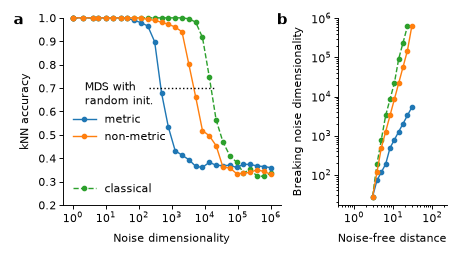

In [2]:
result = robustness.load("main")
accuracy = result.acc.mean(axis=-1)  # mean over the repetitions
dims, threshold = result.dims, result.threshold

# panel a: the extra distance D = 10; panel b: the ten geometric distances of the fit
D_a = int(np.argmin(np.abs(result.Ds - 10.0)))
Ds = result.Ds[: result.n_fit]
breaking_dims = np.array([robustness.breaking_dims(accuracy[m, : result.n_fit], dims, threshold) for m in range(len(robustness.METHODS))])

fig = plt.figure(figsize=(3.25, 1.8))

plt.subplot(1, 3, (1, 2))
(metric_line,) = plt.plot(dims, accuracy[0, D_a], ".-", label="metric", clip_on=False)
(nonmetric_line,) = plt.plot(dims, accuracy[1, D_a], ".-", label="non-metric", clip_on=False)
(classical_line,) = plt.plot(dims, accuracy[2, D_a], ".--", color="tab:green", label="classical", zorder=-1, clip_on=False)
random_init_legend = plt.legend(handles=[metric_line, nonmetric_line], title="MDS with\nrandom init.", loc="center left")
plt.gca().add_artist(random_init_legend)  # a second legend: classical MDS has no random initialization
plt.legend(handles=[classical_line], loc="lower left")
plt.ylim([0.2, 1])
plt.xscale("log")
plt.xlabel("Noise dimensionality")
plt.ylabel("kNN accuracy")
plt.xticks([1, 10, 100, 1000, 10000, 100000, 1000000])
plt.plot([2 * 10**2, 2 * 10**4], [threshold, threshold], "k:")

plt.subplot(1, 3, 3)
plt.plot(Ds, breaking_dims[0], ".-", label="metric MDS")
plt.plot(Ds, breaking_dims[1], ".-", label="non-metric MDS")
plt.plot(Ds, breaking_dims[2], ".--", color="tab:green", label="classical MDS", zorder=-1)  # the line stops at distances where it never breaks
plt.xlabel("Noise-free distance")
plt.ylabel("Breaking noise dimensionality")
plt.yscale("log")
plt.xscale("log")
plt.gca().set_aspect("equal", adjustable="datalim")

fig.text(0.00, 0.93, "a", fontweight="bold", fontsize=8)
fig.text(0.60, 0.93, "b", fontweight="bold", fontsize=8)

plt.savefig(paths.FIGURES / "robustness.png", dpi=300)
plt.savefig(paths.FIGURES / "robustness.pdf")

slope_mmds = robustness.power_law_slope(Ds, breaking_dims[0])
slope_nmds = robustness.power_law_slope(Ds, breaking_dims[1])
print(f"Slope mMDS: {slope_mmds:.1f}")
print(f"Slope nMDS: {slope_nmds:.1f}")
slope_cmds = robustness.power_law_slope(Ds, breaking_dims[2])  # distances at which it never breaks are left out
print(f"Slope classical MDS: {slope_cmds:.1f}")
as_ints = lambda breaking: [int(d) if np.isfinite(d) else None for d in breaking]  # None: never below the threshold
print(f"({result.acc.shape[-1]} repetitions; breaking dimensions: metric {as_ints(breaking_dims[0])}, "
      f"non-metric {as_ints(breaking_dims[1])}, classical {as_ints(breaking_dims[2])})")

## Appendix table: slopes of all settings

One row per setting, in the order of the table: the setting's columns (noise, sigma, jitter, cluster sizes, sampling)
followed by the slope of log(breaking dimensionality) against log(D / sigma) for metric and for non-metric MDS. The
breaking dimensionalities come from the kNN accuracy averaged over the repetitions, as in the figure.

In [3]:
noise_names = {"gaussian": "Gaussian", "uniform": "Uniform", "exponential": "Exponential"}
print("Noise & $\\sigma$ & Jitter & Size & Sampling & mMDS & nMDS & cMDS \\\\")
print("\\midrule")
for name in robustness.CONFIGS:
    try:
        res = robustness.load(name)
    except FileNotFoundError:
        print(f"% {name}: not run yet (uv run python code/mds_robustness.py {name})")
        continue
    c, s = res.config, robustness.slopes(res)
    size = rf"$\sim{c['n']}$" if c["random_sizes"] else f"$={c['n']}$"
    print(f"{noise_names[c['noise']]} & {c['sigma']:.1f} & {'Yes' if c['jitter'] else 'No'} & {size} & "
          f"{'Random' if c['random_sizes'] else 'Fixed'} & {s[0]:.2f} & {s[1]:.2f} & {s[2]:.2f} \\\\  % {res.acc.shape[-1]} repetitions")

Noise & $\sigma$ & Jitter & Size & Sampling & mMDS & nMDS & cMDS \\
\midrule
Gaussian & 1.0 & No & $=99$ & Fixed & 2.24 & 4.11 & 4.75 \\  % 10 repetitions
Gaussian & 1.0 & Yes & $\sim99$ & Random & 2.22 & 4.05 & 4.04 \\  % 10 repetitions
Uniform & 1.0 & Yes & $\sim99$ & Random & 2.22 & 3.98 & 4.07 \\  % 10 repetitions
Exponential & 1.0 & Yes & $\sim99$ & Random & 2.33 & 4.04 & 4.04 \\  % 10 repetitions
Gaussian & 2.0 & Yes & $\sim99$ & Random & 2.33 & 3.94 & 4.23 \\  % 10 repetitions
Gaussian & 1.0 & Yes & $\sim297$ & Random & 2.02 & 3.92 & 3.94 \\  % 10 repetitions


A look at all settings (not saved): the breaking dimensionality against D / sigma should be close to straight lines.

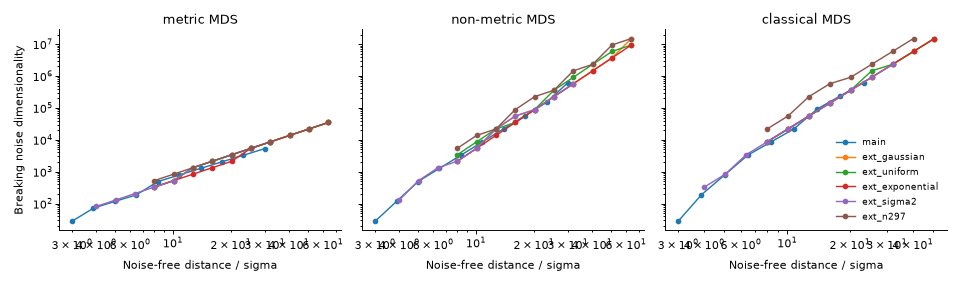

In [4]:
fig, axs = plt.subplots(ncols=3, figsize=(7, 2), layout="constrained", sharey=True)
for name in robustness.CONFIGS:
    try:
        res = robustness.load(name)
    except FileNotFoundError:
        continue
    x = res.Ds[: res.n_fit] / res.sigma
    breaking = robustness.mean_breaking_dims(res)
    for m, ax in enumerate(axs):
        ax.plot(x, breaking[m], ".-", label=name)
for ax, method in zip(axs, robustness.METHODS):
    ax.set(xscale="log", yscale="log", xlabel="Noise-free distance / sigma", title=f"{method} MDS")
axs[0].set_ylabel("Breaking noise dimensionality")
axs[-1].legend(fontsize=5)